# Credit Default Prediction: The Cost of Explainability in Consumer Credit Risk

**Course:** COS802, MIT Big Data Science, University of Pretoria  
**Author:** <Name>, <Student number>  
**Notebook:** 03 Modelling and explainability

## Purpose
This notebook trains and evaluates models on the two feature sets from notebook 02 to answer both research questions. 
It compares performance on application-only versus full features (RQ1), compares an interpretable model against a black-box model (RQ2), 
and uses SHAP to explain the best model's predictions.

## Project research questions
- **RQ1** How much do bureau and repayment history tables improve default prediction over application data alone?
- **RQ2** How much predictive performance is lost when an inherently interpretable model (EBM) is used instead of LightGBM?

## Notebook outline
### 1. Setup
    1.1 Imports and data loading

### 2. Evaluation Setup
    2.1 Cross-validation
    2.2 Metrics

### 3. Baselines
    3.1 Dummy classifier
    3.2 Logistic regression

### 4. RQ1: Application-Only vs Full Features
    4.1 LightGBM on both feature sets

### 5. RQ2: Interpretable vs Black-Box
    5.1 EBM vs LightGBM

### 6. Results Summary

### 7. Explainability
    7.1 SHAP on the best model

### 8. Findings and Limitations

#  

### 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
import shap


import warnings
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

In [2]:
directory = Path(r"C:\Users\mekay\Downloads\COS802 Data")
seed = 27

features_app = pd.read_parquet(directory / "features_app.parquet")
features_full = pd.read_parquet(directory / "features_full.parquet")

print(features_app.shape, features_full.shape)

(307511, 115) (307511, 160)


### 

# 

### 2. Evaluation Setup

2.1 Cross-validation

Models are evaluated using stratified 5-fold cross-validation. Each applicant is used for testing exactly once, and stratification keeps the default rate at 8.07% in every fold. The same folds are used for every model, so differences in performance reflect the model or feature set rather than the data split. Results are reported as the mean and standard deviation across folds.

In [3]:
# Target and stratified 5-fold CV
# Imbalanced data- stratified does K folds in the same proportion split 

y = features_app["TARGET"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

In [4]:
#Drop indentifier and TARGET from our data
X_app = features_app.drop(columns=["SK_ID_CURR", "TARGET"])
X_full = features_full.drop(columns=["SK_ID_CURR", "TARGET"])

# 

2.2 Metrics

Because of the class imbalance, accuracy is not used. Models are compared on four metrics:

- **ROC-AUC:** how well the model ranks defaulters above repayers overall (0.5 = random, 1 = perfect).
- **PR-AUC:** the same idea, but focused on the defaulter class, so more sensitive under imbalance. A random model scores about 0.08 (the default rate).
- **Precision:** of the applicants flagged as likely defaulters, the share that actually defaulted.
- **Recall:** of the applicants who actually defaulted, the share the model flagged.

In [5]:
#Creating a function that will assess the models we train
scoring_metrics = ["roc_auc", "average_precision", "precision", "recall"]

def evaluate_model(model, X, y, cv):
    """Run the model through the CV folds and return the mean and std of each metric."""
    results = cross_validate(model, X, y, cv=cv, scoring=scoring_metrics)
    return pd.DataFrame(results).agg(["mean", "std"])

# 

## 3. Baselines

### 3.1 Dummy Classifier

The dummy classifier ignores all features and predicts the overall default rate for every applicant. It sets the floor that any useful model must beat.

In [6]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="prior")
dummy_results = evaluate_model(dummy, X_app, y, cv)
dummy_results

,fit_time,score_time,test_roc_auc,test_average_precision,test_precision,test_recall
mean,0.181922,0.032006,0.5,8.072882e-02,0.0,0.0
std,0.014357,0.004434,0.0,5.870143e-07,0.0,0.0


# 

### 3.2 Logistic Regression

In [7]:
# One hot encoding the text columns so we can feed it into our model
X_app_lr = pd.get_dummies(X_app, dummy_na=False)
X_full_lr = pd.get_dummies(X_full, dummy_na=False)

#Pipeline to clean up and scale our data before training it
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))

lr_app_results = evaluate_model(lr, X_app_lr, y, cv)
lr_full_results = evaluate_model(lr, X_full_lr, y, cv)

In [8]:
lr_app_results

,fit_time,score_time,test_roc_auc,test_average_precision,test_precision,test_recall
mean,36.176989,4.744625,0.746686,0.221487,0.160493,0.675811
std,5.647448,1.903233,0.003352,0.002450,0.001193,0.005261


In [9]:
lr_full_results

,fit_time,score_time,test_roc_auc,test_average_precision,test_precision,test_recall
mean,29.459160,4.759681,0.765465,0.244092,0.170491,0.695307
std,1.353421,1.158490,0.002390,0.003701,0.001585,0.004019


Logistic regression clearly outperforms the dummy classifier. On application data alone it achieves a ROC-AUC of 0.747 and a PR-AUC of 0.221. Adding the supporting tables raises these to 0.765 and 0.244, an improvement several times larger than the variation between folds. With class weighting, the model identifies around 68% to 70% of defaulters, at a precision of 16% to 17%, roughly double the base default rate.                           

# 

## 4. Application-Only vs Full Features


### 4.1 LightGBM on both feature sets

In [10]:
# LightGBM reads text columns as pandas "category" type, so convert them (on copies, so X_app/X_full stay unchanged)
X_app_lgb = X_app.copy() #Create copies as we later transform datatypes
X_full_lgb = X_full.copy()

#LightGBM needs to distiguish which columns are non-numeric so it can treat it accordingly
cat_cols = X_app_lgb.select_dtypes("object").columns
X_app_lgb[cat_cols] = X_app_lgb[cat_cols].astype("category")
X_full_lgb[cat_cols] = X_full_lgb[cat_cols].astype("category")

lgbm = lgb.LGBMClassifier(
    n_estimators=500, # Number of trees
    learning_rate=0.05, # How much each tree corrects the previous ones
    num_leaves=31, # Complexity of each tree
    class_weight="balanced", # Weight defaulters more, as with LR
    random_state=seed,
    verbose=-1, # Hide training logs
)

lgb_app_results = evaluate_model(lgbm, X_app_lgb, y, cv)
lgb_full_results = evaluate_model(lgbm, X_full_lgb, y, cv)

display(lgb_app_results, lgb_full_results)

,fit_time,score_time,test_roc_auc,test_average_precision,test_precision,test_recall
mean,39.783379,2.734278,0.757035,0.240634,0.178403,0.634804
std,15.416082,1.581972,0.003095,0.003875,0.001591,0.006476


,fit_time,score_time,test_roc_auc,test_average_precision,test_precision,test_recall
mean,54.568121,2.260957,0.778397,0.269311,0.193452,0.649748
std,5.208395,1.164981,0.003238,0.005804,0.001444,0.007389


LightGBM outperforms logistic regression on both feature sets. Adding the supporting tables raises its ROC-AUC from 0.757 to 0.778 and its PR-AUC from 0.241 to 0.269, an improvement roughly seven times the variation between folds. Logistic regression shows a similar gain (0.747 to 0.765), so the benefit of the additional tables holds across both models. The gain from the additional data is larger than the gain from moving to the more complex model.

# 

## 5. RQ2: Interpretable vs Black-Box

### 5.1 Explainable Boosting Machine

An Explainable Boosting Machine (EBM) is trained on the full feature set and compared with LightGBM. EBM is a glass-box model: its prediction is a sum of one learned curve per feature, plus a small number of pairwise interactions, so each feature's effect can be read directly. Defaulters are weighted to match the class balancing used for the other models.

In [11]:
weights = compute_sample_weight("balanced", y)

ebm = ExplainableBoostingClassifier(
    interactions=10, # Allow 10 pairwise interactions (keeps it interpretable and faster)
    outer_bags=4, # Fewer bagging rounds than the default, to cut training time
    n_jobs=-1, # Use all CPU cores
    random_state=seed,
)

ebm_cv = cross_validate(ebm, X_full, y, cv=cv, scoring=scoring_metrics, params={"sample_weight": weights})
ebm_full_results = pd.DataFrame(ebm_cv).agg(["mean", "std"])

display(ebm_full_results, lgb_full_results)

C:\Users\mekay\anaconda3\envs\Mekayl\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(
C:\Users\mekay\anaconda3\envs\Mekayl\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(
C:\Users\mekay\anaconda3\envs\Mekayl\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected. Our visualiz

,fit_time,score_time,test_roc_auc,test_average_precision,test_precision,test_recall
mean,268.647041,1.314518,0.779452,0.270443,0.180957,0.696999
std,34.989125,1.158615,0.003066,0.006666,0.001569,0.007522


,fit_time,score_time,test_roc_auc,test_average_precision,test_precision,test_recall
mean,54.568121,2.260957,0.778397,0.269311,0.193452,0.649748
std,5.208395,1.164981,0.003238,0.005804,0.001444,0.007389


EBM achieves a ROC-AUC of 0.779 and a PR-AUC of 0.270, against 0.778 and 0.269 for LightGBM. The differences are well within the variation between folds, so the two models perform equivalently: on this data, the interpretable model costs nothing in predictive performance. The main cost is training time, with EBM taking roughly five to six times longer per fold. Both models were trained with standard settings, so a heavily tuned LightGBM may still gain a small advantage.

# 

In [12]:
summary = pd.DataFrame({
    "Dummy": dummy_results.loc["mean"],
    "LR (application)": lr_app_results.loc["mean"],
    "LR (full)": lr_full_results.loc["mean"],
    "LightGBM (application)": lgb_app_results.loc["mean"],
    "LightGBM (full)": lgb_full_results.loc["mean"],
    "EBM (full)": ebm_full_results.loc["mean"],
}).T

summary[["test_roc_auc", "test_average_precision", "test_precision", "test_recall"]].round(3)

,test_roc_auc,test_average_precision,test_precision,test_recall
Dummy,0.500,0.081,0.000,0.000
LR (application),0.747,0.221,0.160,0.676
LR (full),0.765,0.244,0.170,0.695
LightGBM (application),0.757,0.241,0.178,0.635
LightGBM (full),0.778,0.269,0.193,0.650
EBM (full),0.779,0.270,0.181,0.697


The table answers both research questions. **RQ1:** adding the supporting tables improves both logistic regression (0.747 to 0.765 ROC-AUC) and LightGBM (0.757 to 0.778), so bureau and repayment history add predictive value beyond the application data. **RQ2:** EBM matches LightGBM on the full feature set (0.779 vs 0.778 ROC-AUC), so the interpretable model costs no predictive performance. The best models reach a Gini of about 0.56 (Gini = 2 × ROC-AUC − 1).

# 

## 7. Explainability

### 7.1 Global Feature Importance

LightGBM is a black box, so its predictions are explained after training using SHAP (SHapley Additive exPlanations), which assigns each feature a contribution to each prediction. A final LightGBM model is trained on the full feature set, and SHAP values are calculated for a random sample of 5,000 applicants. 

EBM needs no separate explanation method. Its prediction is a sum of one contribution per feature, so its built-in importances are exact rather than approximated. Both importance measures are on the same scale, the average absolute effect on the log-odds of default, so the two models can be compared directly.

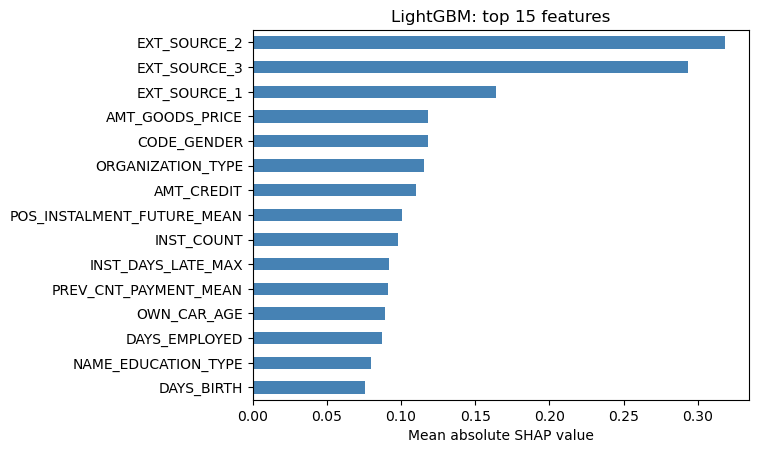

In [13]:
# Cross-validation doesn't keep trained models, so fit one final LightGBM on all the data
lgbm.fit(X_full_lgb, y)

# SHAP values on a sample of 5,000 applicants, for speed
X_sample = X_full_lgb.sample(5000, random_state=seed)
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer(X_sample)

# Importance = mean absolute SHAP value per feature (same scale as EBM's importances)
lgb_importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_sample.columns).sort_values(ascending=False)

lgb_importance.head(15).sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Mean absolute SHAP value")
plt.title("LightGBM: top 15 features")
plt.show()

# 

C:\Users\mekay\anaconda3\envs\Mekayl\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


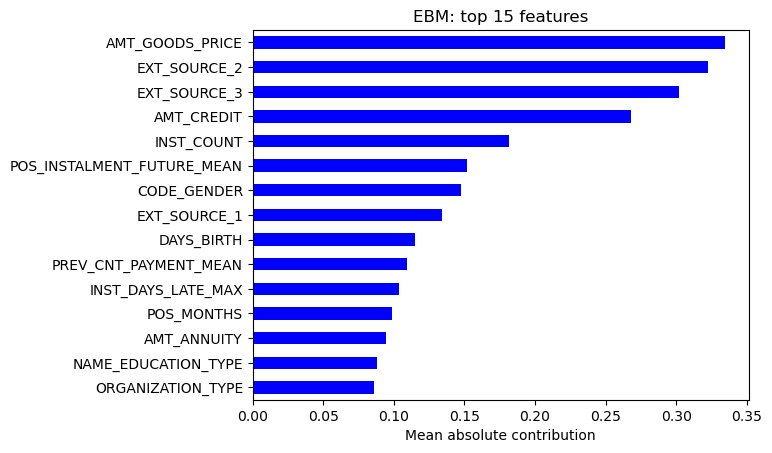

In [14]:
# Fit one final EBM on all the data, with the same settings the model trained earlier
weights = compute_sample_weight("balanced", y)
ebm = ExplainableBoostingClassifier(interactions=10, outer_bags=4, n_jobs=-1, random_state=seed)
ebm.fit(X_full, y, sample_weight=weights)

# EBM's built-in importance: mean absolute contribution per feature
ebm_importance = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values(ascending=False)

ebm_importance.head(15).sort_values().plot(kind="barh", color="blue")
plt.xlabel("Mean absolute contribution")
plt.title("EBM: top 15 features")
plt.show()

# 

### 7.2 Comparison

Both models rely on largely the same features: 13 of their top 15 overlap. The external source scores dominate both, and several supporting-table features (instalment counts, maximum days late, and loan-term features) rank highly in each, confirming the source of the RQ1 improvement. `CODE_GENDER` ranks fifth for LightGBM and seventh for EBM, however, gender is a protected ground under South African anti-discrimination law so a lender could not defend a model that relies on it.

The main difference is the weight placed on `AMT_GOODS_PRICE` and `AMT_CREDIT`, which EBM rates far more highly. LightGBM's trees can combine the two features directly, whereas EBM must model each one separately. 

# 

## 8. Findings and Limitations

### 8.1 Findings

**RQ1: Do bureau and repayment history tables improve default prediction over application data alone?**
Yes. Adding the supporting tables raised ROC-AUC by around 0.02 for both logistic regression (0.747 to 0.765) and LightGBM (0.757 to 0.778), with similar gains in PR-AUC. The improvement is several times larger than the variation between folds and holds across both models. Feature importances show that it comes mainly from repayment behaviour: instalment counts, maximum days late, and loan-term features. The gain from adding data was larger than the gain from moving to a more complex model.

**RQ2: How much predictive performance is lost when an interpretable model is used instead of LightGBM?**
None measurable. EBM matched LightGBM on the full feature set (0.779 vs 0.778 ROC-AUC, 0.270 vs 0.269 PR-AUC), with differences well within the variation between folds. The cost of interpretability here was training time rather than accuracy, with EBM taking roughly five to six times longer per fold. Both models also relied on largely the same features.

**Explainability in practice:** both models used `CODE_GENDER` as a top-10 feature. EBM made this immediately visible, whereas for LightGBM it only became apparent through SHAP. In a regulated lending context, where the National Credit Act prohibits unfair discrimination and lenders must be able to explain decisions, this transparency is a practical advantage, not only a theoretical one.

### 8.2 Limitations

- **Untuned models:** all models used standard settings. Tuning may improve LightGBM slightly more than EBM.
- **Reduced EBM settings:** EBM was trained with fewer bags than its default to keep training time practical.
- **Protected attributes:** the models include gender and age, which would not be acceptable in a production credit model.
- **Data context:** the Home Credit data is not South African, so the results may not transfer directly to the local market.
- **Probability calibration:** class weighting means the predicted probabilities are not true default probabilities.

### 8.3 Future Work

- Remove protected attributes and assess fairness across demographic groups.
- Add a loan-to-goods ratio feature, which EBM's reliance on `AMT_GOODS_PRICE` and `AMT_CREDIT` suggests would be useful.
- Tune both models to test whether the RQ2 result holds under optimised settings.
- Validate the approach on South African credit data.